![Banner](../../../../Images/Banner/07_remote_sensing/09_06_banner_rs_lidar.png)


# Point Cloud Classification with Machine Learning and Deep Learning

Rule-based filters handle one class at a time: ground, buildings, wires. Supervised learning labels every point at once, learning from examples which combinations of local geometry, height and return structure mark ground, vegetation, buildings and other objects. This notebook trains random forest and gradient-boosting classifiers on hand-crafted point features, and PointNet and PointNet++ deep networks on raw points on the GPU, with `geolattice.rsense.lidar` and `geolattice.rsense.dl.pointnet`. All models are trained on one part of the Autzen survey and tested on a separate area they have never seen.


## Overview

### The task

**Semantic segmentation** of a point cloud assigns a class to every point. It is the 3D counterpart of pixel classification in images, but the input is unordered, irregular and of varying density, so image methods do not apply directly. Two families of methods are in use:

1. **Feature-based machine learning.** For every point, describe its neighbourhood with hand-crafted features, then train a standard classifier (random forest, gradient boosting, support vector machine) on labelled points.
2. **Deep learning on points.** Networks consume the coordinates and attributes of the points directly and learn their own features.

### Hand-crafted point features

| Group | Features | What they capture |
|---|---|---|
| Height | Height above ground (from a DEM), absolute elevation | Ground versus objects; low versus high vegetation |
| Return structure | Return number, number of returns | Porous objects (vegetation) versus solid surfaces |
| Intensity | Echo strength | Material (asphalt, grass, roofing), partly |
| Covariance (eigenvalue) features | Linearity, planarity, scattering, omnivariance, anisotropy, eigenentropy, change of curvature, verticality, normal z | Local shape: lines, planes, volumes, walls |
| Multi-scale | The same features at several neighbourhood sizes $k$ | Objects of different sizes (a roof edge at $k = 10$, the whole roof at $k = 50$) |

With eigenvalues $\lambda_1 \ge \lambda_2 \ge \lambda_3$ of the covariance of the $k$ nearest neighbours (Weinmann et al. 2015): linearity $= (\lambda_1 - \lambda_2)/\lambda_1$, planarity $= (\lambda_2 - \lambda_3)/\lambda_1$, scattering $= \lambda_3/\lambda_1$, omnivariance $= (\lambda_1\lambda_2\lambda_3)^{1/3}$, eigenentropy $= -\sum e_i \ln e_i$ with $e_i = \lambda_i/\sum\lambda$.

### Deep learning on point clouds

- **PointNet** (Qi et al. 2017a) applies the same small multi-layer perceptron to every point, then a symmetric function (max pooling) over all points gives a global feature that does not depend on point order. For segmentation, each point's own feature is concatenated with the global feature and classified. PointNet sees each point and the whole block, but no local neighbourhoods.
- **PointNet++** (Qi et al. 2017b) adds hierarchy: it samples centroids (farthest point sampling), groups the points in a ball around each centroid, runs a mini-PointNet on each group, and repeats at coarser levels (set abstraction); feature propagation then interpolates the features back to every point. Like a CNN, it learns local patterns at several scales.
- Later networks include **KPConv** (kernel point convolutions), **RandLA-Net** (fast random sampling for large scenes), sparse **voxel CNNs** (MinkowskiNet) and **point transformers**, available in libraries such as Open3D-ML and torch-points3d.

Networks work on fixed-size **blocks**: the scene is cut into squares (here 20 m), a fixed number of points is sampled from each, coordinates are normalised within the block, and predictions from overlapping blocks are averaged.

### Validation without leakage

Neighbouring points share almost the same features and labels. A random split of points into training and test sets puts near-identical neighbours on both sides and reports accuracies that will not hold in a new area. Here the scene is split **spatially**: a western training area, a validation strip and an eastern test area separated by gaps.


## Point Classification with GeoLattice


### Learning objectives

1. Prepare labels and a leakage-free spatial split of a point cloud.
2. Compute multi-scale eigenvalue and attribute features for every point and inspect their importance.
3. Train random forest and gradient-boosting point classifiers and evaluate them on a separate area.
4. Show how a random point-wise holdout overestimates accuracy.
5. Train PointNet and PointNet++ on the GPU and compare them with the feature-based models.
6. Map and inspect classification errors and export the classified cloud.


### Data

| File | Content |
|---|---|
| `autzen_window.laz` | A 440 m x 440 m window of the Autzen Stadium survey, Eugene, Oregon: 1.36 million points, about 7 points/m², with ground (2), high vegetation (5), buildings (6) and unclassified objects (0) labelled by the producer, plus small numbers of water, bridge and user-defined points |

A GPU is used for PointNet and PointNet++ when available; the feature-based models run on the CPU.


### Contents

1. Setup
2. Labels and a spatial split
3. Height above ground without using the labels
4. Point features
5. Random forest and gradient boosting
6. Why a random holdout misleads
7. Which features matter
8. PointNet and PointNet++ on the GPU
9. Comparing all models
10. Where the models go wrong
11. Exporting the classified cloud
12. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

import time  # timing
import numpy as np  # arrays
import pandas as pd  # tables
import rasterio  # raster I/O
import matplotlib.pyplot as plt  # figures
import torch  # deep learning
from torch.utils.data import DataLoader  # mini-batches
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score, confusion_matrix, jaccard_score  # metrics

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.dl import pointnet as pn  # PointNet and PointNet++

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
torch.manual_seed(0); np.random.seed(0)  # reproducible runs
print("geolattice.rsense", rs.__version__, "| torch", torch.__version__, "| device:", DEVICE,  # summary line
      torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")  # versions and device

geolattice.rsense 0.3.35 | torch 2.14.0+cu132 | device: cuda NVIDIA RTX A5500 Laptop GPU


In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

AUTZEN = DATA / "autzen_window.laz"  # labelled urban window, UTM 10N

## Labels and a spatial split

The producer's codes are mapped to four classes. Points with rare codes (water, bridge deck and user-defined classes, together under 1 %) are excluded from training and scoring (label 0).

| Label | Producer codes | Meaning |
|---|---|---|
| 1 other | 0 (created, never classified) | Cars, fences, low structures and anything the producer did not label |
| 2 ground | 2 | Bare earth, roads, parking |
| 5 vegetation | 5 | Trees and tall shrubs |
| 6 building | 6 | Roofs and walls |


,train,validation,test
building,44961,221,5260
ground,433686,167106,365495
other,38810,44447,42637
vegetation,44917,41087,64658
points,567721,254392,478705


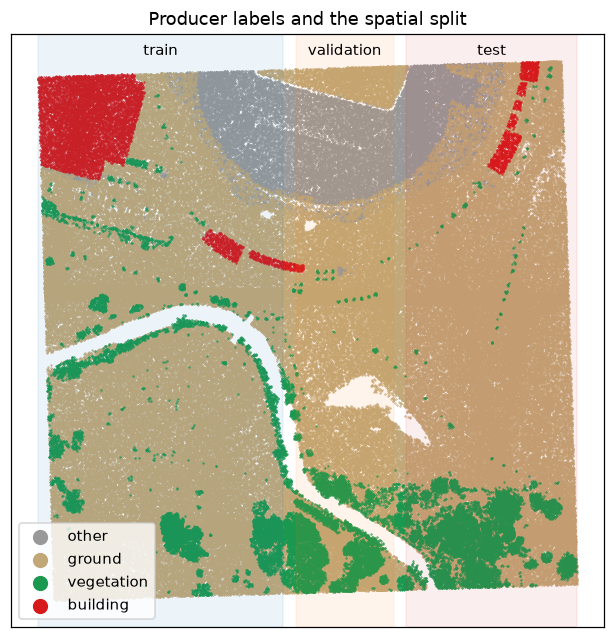

In [3]:
pc = rs.lidar.read_las(AUTZEN).drop_noise()  # the labelled window
c = np.asarray(pc["classification"])  # producer codes
label = np.select([c == 0, c == 2, c == 5, c == 6], [1, 2, 5, 6], 0).astype("uint8")  # 4 classes, 0 = excluded
pc = pc.with_field("label", label)  # store it as a field
NAMES = {1: "other", 2: "ground", 5: "vegetation", 6: "building"}  # class names
CLASSES = list(NAMES)  # class codes in order

x0, y0, x1, y1 = pc.bbox  # extent
AREAS = {"train": (x0, x0 + 200), "validation": (x0 + 210, x0 + 290), "test": (x0 + 300, x1)}  # west to east, 10 m gaps
parts = {k: pc.crop(a, y0, b_, y1) for k, (a, b_) in AREAS.items()}  # the three areas
counts = pd.DataFrame({k: pd.Series(np.asarray(v["label"])).map(NAMES).value_counts() for k, v in parts.items()})  # per area
counts.loc["points"] = [len(v) for v in parts.values()]  # totals
display(counts.fillna(0).astype(int))  # class counts per area

fig, ax = plt.subplots(figsize=(8, 7))  # one panel
cols = {1: "#999999", 2: "#c2a878", 5: "#1a9850", 6: "#d7191c"}  # class colours
s = pc.filter(np.random.default_rng(0).random(len(pc)) < 0.2)  # 20 % of the points for plotting
for k, col in cols.items():  # each class
    m = np.asarray(s["label"]) == k  # its points
    ax.scatter(s.x[m], s.y[m], s=0.2, color=col, label=NAMES[k])  # plan view
for k, (a, b_) in AREAS.items():  # area boundaries
    ax.axvspan(a, b_, color={"train": "C0", "validation": "C1", "test": "C3"}[k], alpha=0.08)  # shaded strip
    ax.text((a + b_) / 2, y1 + 5, k, ha="center")  # its name
ax.set(aspect="equal", xticks=[], yticks=[], title="Producer labels and the spatial split")  # labels
ax.legend(markerscale=20, loc="lower left"); plt.show()  # draw

## Height above ground without using the labels

Height above ground is the strongest single feature, but computing it from the producer's ground class would leak the labels into the features. Instead the DEM comes from SMRF (with a 100 m window for the large roofs), which uses only geometry.


In [4]:
t0 = time.perf_counter()  # start the timer
g = rs.lidar.smrf(pc, cell=2.0, slope=0.15, window=100)  # label-free ground classification
dem = rs.lidar.dem(g, 1.0)  # DEM from SMRF ground
pc = rs.lidar.normalize_heights(pc, dem)  # adds "height"
parts = {k: pc.crop(a, y0, b_, y1) for k, (a, b_) in AREAS.items()}  # re-cut the areas with the new field
print(f"SMRF DEM and heights in {time.perf_counter() - t0:.1f} s")  # timing

SMRF DEM and heights in 37.3 s


## Point features

`rs.lidar.point_feature_table` returns one row per point with the attributes (height, intensity, returns) and eigenvalue features at each neighbourhood size in `scales`. Two scales, $k = 10$ and $k = 40$, capture small details and larger structures.


In [5]:
SCALES = (10, 40)  # neighbourhood sizes
ATTRS = ("height", "intensity", "return_number", "number_of_returns")  # point attributes used
t0 = time.perf_counter()  # start the timer
feat = {k: rs.lidar.point_feature_table(v, scales=SCALES, attrs=ATTRS, label="label") for k, v in parts.items()}  # tables
# summary line
print(f"features for {sum(len(f) for f in feat.values()):,} points in {time.perf_counter() - t0:.0f} s; "
      f"{feat['train'].shape[1] - 1} features")  # size
FEATURES = [c for c in feat["train"].columns if c != "label"]  # feature names
# median features per class
feat["train"].groupby(feat["train"].label.map(NAMES))[["height", "number_of_returns", "k10_planarity",
                                                        "k10_scattering", "k40_verticality"]].median().round(3)  # medians

features for 1,300,818 points in 26 s; 22 features


,height,number_of_returns,k10_planarity,k10_scattering,k40_verticality
label,,,,,
building,0.015,1.0,0.513,0.005,0.063
ground,-0.001,1.0,0.507,0.003,0.001
other,0.116,1.0,0.497,0.020,0.081
vegetation,5.629,2.0,0.309,0.123,0.295


## Random forest and gradient boosting

`rs.lidar.train_point_classifier` computes the features on the training cloud, fits the model (here on 200,000 sampled points) and reports accuracy on a random holdout of the training area. `rs.lidar.predict_point_classes` then computes the features on the unseen test area and labels its points. The scores on the test area are the honest ones.


In [6]:
train_pc = parts["train"].filter(np.asarray(parts["train"]["label"]) > 0)  # labelled training points
test_pc = parts["test"]  # the unseen eastern area
y_test = np.asarray(test_pc["label"]); scored = y_test > 0  # test labels and scored points

def test_scores(pred, name, seconds):  # metrics on the test area
    p, t = pred[scored], y_test[scored]  # scored points
    f1 = f1_score(t, p, labels=CLASSES, average=None)  # per-class F1
    return {"model": name, "OA": accuracy_score(t, p), "kappa": cohen_kappa_score(t, p),  # overall scores
            "mean IoU": jaccard_score(t, p, labels=CLASSES, average="macro"),
            **{f"F1 {NAMES[k]}": v for k, v in zip(CLASSES, f1)}, "seconds": seconds}

results, fitted, preds = [], {}, {}  # scores, models and predictions
for name, kw in (("random forest", dict(model="rf", n_estimators=200, n_jobs=-1)),  # random forest
                 ("XGBoost", dict(model="xgb", n_estimators=300, max_depth=8, learning_rate=0.1))):  # gradient boosting
    t0 = time.perf_counter()  # start the timer
    fit = rs.lidar.train_point_classifier(train_pc, "label", scales=SCALES, sample=200_000, **kw)  # fit
    out = rs.lidar.predict_point_classes(test_pc, fit, field="pred")  # label the test area
    sec = time.perf_counter() - t0  # time for both
    fitted[name], preds[name] = fit, np.asarray(out["pred"])  # keep them
    results.append({**test_scores(preds[name], name, sec), "random-holdout OA": fit["report"]["accuracy"]})  # scores
pd.DataFrame(results).set_index("model").round(3)  # show the comparison

,OA,kappa,mean IoU,F1 other,F1 ground,F1 vegetation,F1 building,seconds,random-holdout OA
model,,,,,,,,,
random forest,0.938,0.834,0.736,0.649,0.972,0.913,0.809,37.902,0.980
XGBoost,0.940,0.840,0.723,0.662,0.971,0.927,0.741,23.844,0.983


## Why a random holdout misleads

The `random-holdout OA` column is the accuracy on randomly withheld points of the **training** area; `OA` is the accuracy on the separate test area. The cell makes the effect explicit for the random forest by comparing accuracy on (a) a random holdout of training points, (b) the validation strip 10 m away and (c) the test area 10 m beyond that.


In [7]:
rf = fitted["random forest"]  # the fitted random forest
val_pc = parts["validation"]  # the strip between training and test areas
val_pred = np.asarray(rs.lidar.predict_point_classes(val_pc, rf, field="pred")["pred"])  # its predictions
yv = np.asarray(val_pc["label"]); mv = yv > 0  # validation labels
pd.Series({"random holdout inside the training area": rf["report"]["accuracy"],  # optimistic
           "validation strip (separate area)": accuracy_score(yv[mv], val_pred[mv]),  # honest
           "test area (separate area)": accuracy_score(y_test[scored], preds["random forest"][scored])},  # honest
          name="overall accuracy").round(3).to_frame()

,overall accuracy
random holdout inside the training area,0.980
validation strip (separate area),0.944
test area (separate area),0.938


## Which features matter

Impurity-based importances of the random forest show which features carry the most information. Height dominates; return structure and the eigenvalue features at both scales separate buildings from trees.


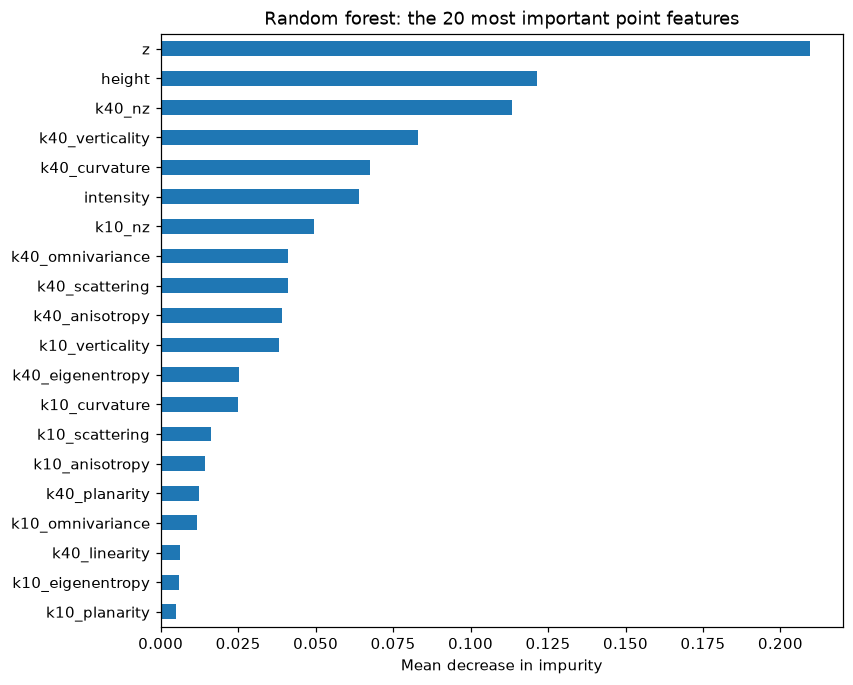

In [8]:
model = rf["model"].model  # the underlying scikit-learn forest
imp = pd.Series(model.feature_importances_, index=rf["features"]).sort_values()  # importances
fig, ax = plt.subplots(figsize=(8, 7))  # one panel
imp.tail(20).plot.barh(ax=ax, color="C0")  # the 20 most important features
ax.set(xlabel="Mean decrease in impurity", title="Random forest: the 20 most important point features"); plt.show()  # draw

## PointNet and PointNet++ on the GPU

`pn.PointBlockDataset` cuts the clouds into 20 m blocks and samples 4,096 points per block; each sample has the block-normalised x, y, z and the standardised attributes (height, intensity, return number, number of returns) as channels. With `augment=True` blocks are randomly rotated about the vertical axis, mirrored and jittered, and `samples_per_block=4` draws four different samples per block per epoch. Points with label 0 are ignored in the loss. The validation strip selects the best epoch; `pn.predict_point_segmentation` sweeps overlapping blocks over the test area and averages the softmax scores of several random passes (`votes`).


In [9]:
FEATS = ("height", "intensity", "return_number", "number_of_returns")  # per-point channels besides xyz
# training blocks with augmentation
ds_train = pn.PointBlockDataset([parts["train"]], label="label", block_size=20.0, num_points=4096, features=FEATS,
                                ignore=(0,), samples_per_block=4, augment=True, seed=0)  # training blocks
# validation blocks with the training scaling
ds_val = pn.PointBlockDataset([parts["validation"]], label="label", block_size=20.0, num_points=4096, features=FEATS,
                              ignore=(0,), classes=ds_train.classes, stats=ds_train.stats)  # same classes and scaling
# summary line
print(f"classes {list(ds_train.classes)} | training samples per epoch {len(ds_train)} | validation samples {len(ds_val)}")
item = ds_train[0]  # one sample
print({k: tuple(v.shape) for k, v in item.items()})  # its tensors

EPOCHS = 30 if DEVICE == "cuda" else 5  # fewer epochs on a CPU
nets, hist = {}, {}  # trained networks and histories
for name, net in (("PointNet", pn.PointNetSeg(item["points"].shape[0], len(ds_train.classes))),  # vanilla PointNet
                  ("PointNet++", pn.PointNet2Seg(item["points"].shape[0], len(ds_train.classes)))):  # hierarchical
    torch.manual_seed(0)  # same start for both
    t0 = time.perf_counter()  # start the timer
    hist[name] = pn.train_point_segmentation(net, DataLoader(ds_train, batch_size=16, shuffle=True),  # training batches
                                             DataLoader(ds_val, batch_size=16), epochs=EPOCHS,  # validation batches
                                             num_classes=len(ds_train.classes), device=DEVICE, log_every=10)
    hist[name]["seconds"] = time.perf_counter() - t0  # training time
    nets[name] = net  # keep the best-validation weights
    # summary line
    print(f"{name}: {sum(p.numel() for p in net.parameters()):,} parameters, trained in {hist[name]['seconds']:.0f} s")

classes [np.uint8(1), np.uint8(2), np.uint8(5), np.uint8(6)] | training samples per epoch 880 | validation samples 88
{'points': (7, 4096), 'index': (4096,), 'labels': (4096,)}


epoch 10/30 loss 0.1280 val mIoU 0.615


epoch 20/30 loss 0.0972 val mIoU 0.631


epoch 30/30 loss 0.0816 val mIoU 0.645
PointNet: 871,748 parameters, trained in 103 s


epoch 10/30 loss 0.1386 val mIoU 0.646


epoch 20/30 loss 0.0899 val mIoU 0.656


epoch 30/30 loss 0.0670 val mIoU 0.664
PointNet++: 437,796 parameters, trained in 227 s


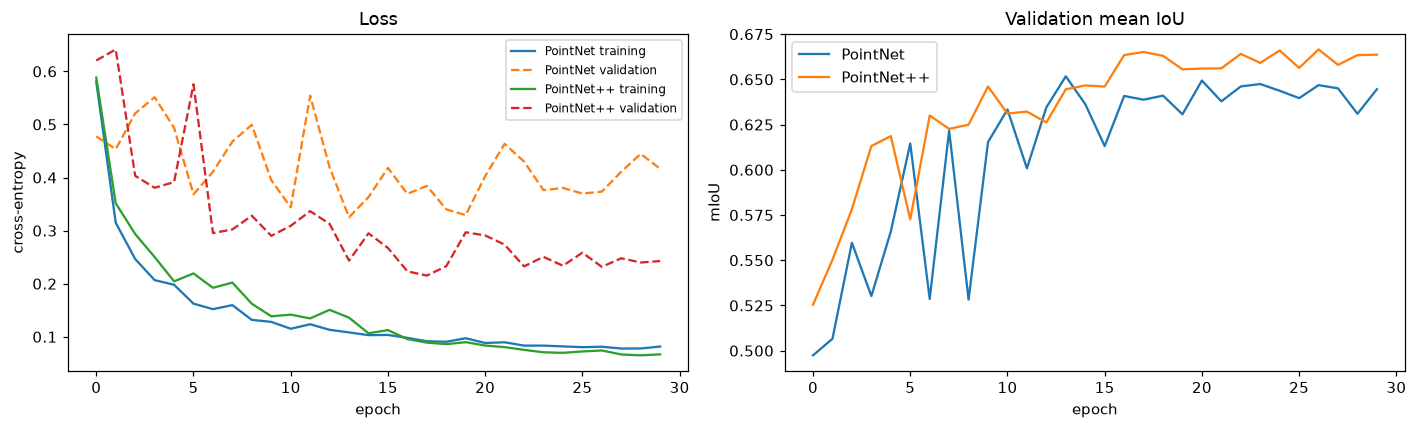

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))  # two panels
for name, h in hist.items():  # each network
    axes[0].plot(h["train_loss"], label=f"{name} training"); axes[0].plot(h["val_loss"], "--", label=f"{name} validation")  # losses
    axes[1].plot(h["val_miou"], label=name)  # validation mIoU
axes[0].set(xlabel="epoch", ylabel="cross-entropy", title="Loss"); axes[0].legend(fontsize=8)  # labels
axes[1].set(xlabel="epoch", ylabel="mIoU", title="Validation mean IoU"); axes[1].legend()  # labels
plt.tight_layout(); plt.show()  # draw

for name, net in nets.items():  # each network
    t0 = time.perf_counter()  # start the timer
    out = pn.predict_point_segmentation(net, test_pc, ds_train, field="pred", votes=3, device=DEVICE)  # label the test area
    preds[name] = np.asarray(out["pred"])  # predicted codes
    results.append(test_scores(preds[name], name, hist[name]["seconds"] + time.perf_counter() - t0))  # scores

## Comparing all models

All four models are scored on the same unseen test area. Overall accuracy (OA) is dominated by the large ground class; the mean IoU and the per-class F1 scores show how well the smaller classes (buildings, other objects) are recognised.


,OA,kappa,mean IoU,F1 other,F1 ground,F1 vegetation,F1 building,seconds
model,,,,,,,,
random forest,0.938,0.834,0.736,0.649,0.972,0.913,0.809,37.902
XGBoost,0.940,0.840,0.723,0.662,0.971,0.927,0.741,23.844
PointNet,0.926,0.800,0.673,0.749,0.962,0.865,0.576,106.605
PointNet++,0.931,0.810,0.671,0.702,0.963,0.902,0.562,245.205


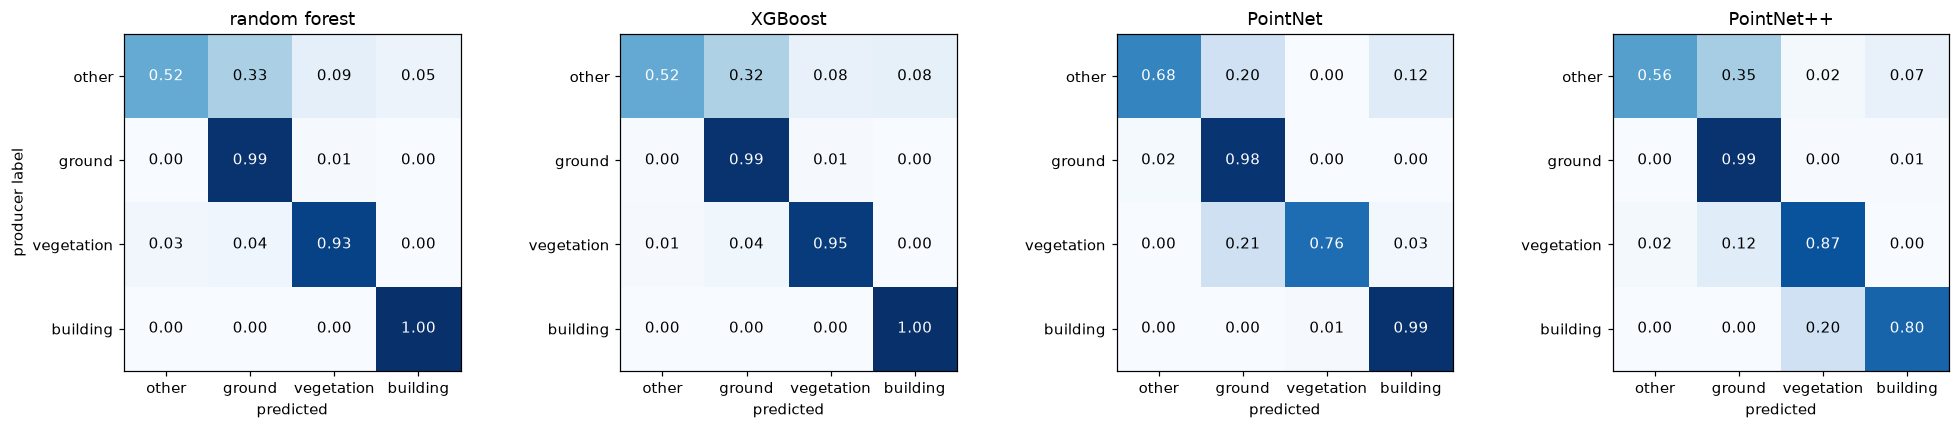

In [11]:
cmp = pd.DataFrame(results).set_index("model").drop(columns="random-holdout OA", errors="ignore").round(3)  # all models
display(cmp)  # the comparison table
fig, axes = plt.subplots(1, len(preds), figsize=(4.6 * len(preds), 4))  # one confusion matrix per model
for ax, (name, p) in zip(axes, preds.items()):  # each model
    cm = confusion_matrix(y_test[scored], p[scored], labels=CLASSES, normalize="true")  # row-normalised
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)  # heat map
    for i in range(len(CLASSES)):  # rows
        for j in range(len(CLASSES)):  # columns
            # label
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set(xticks=range(4), yticks=range(4), xticklabels=NAMES.values(), yticklabels=NAMES.values(),  # labels
           xlabel="predicted", title=name)
axes[0].set_ylabel("producer label"); plt.tight_layout(); plt.show()  # draw

## Where the models go wrong

Mapping the errors in the test area shows where the classes are confused: building edges and walls (between building, vegetation and other), low objects near the ground (between other and ground), and trees overhanging roofs. A cross-section through the area compares the labels with the best model's prediction.


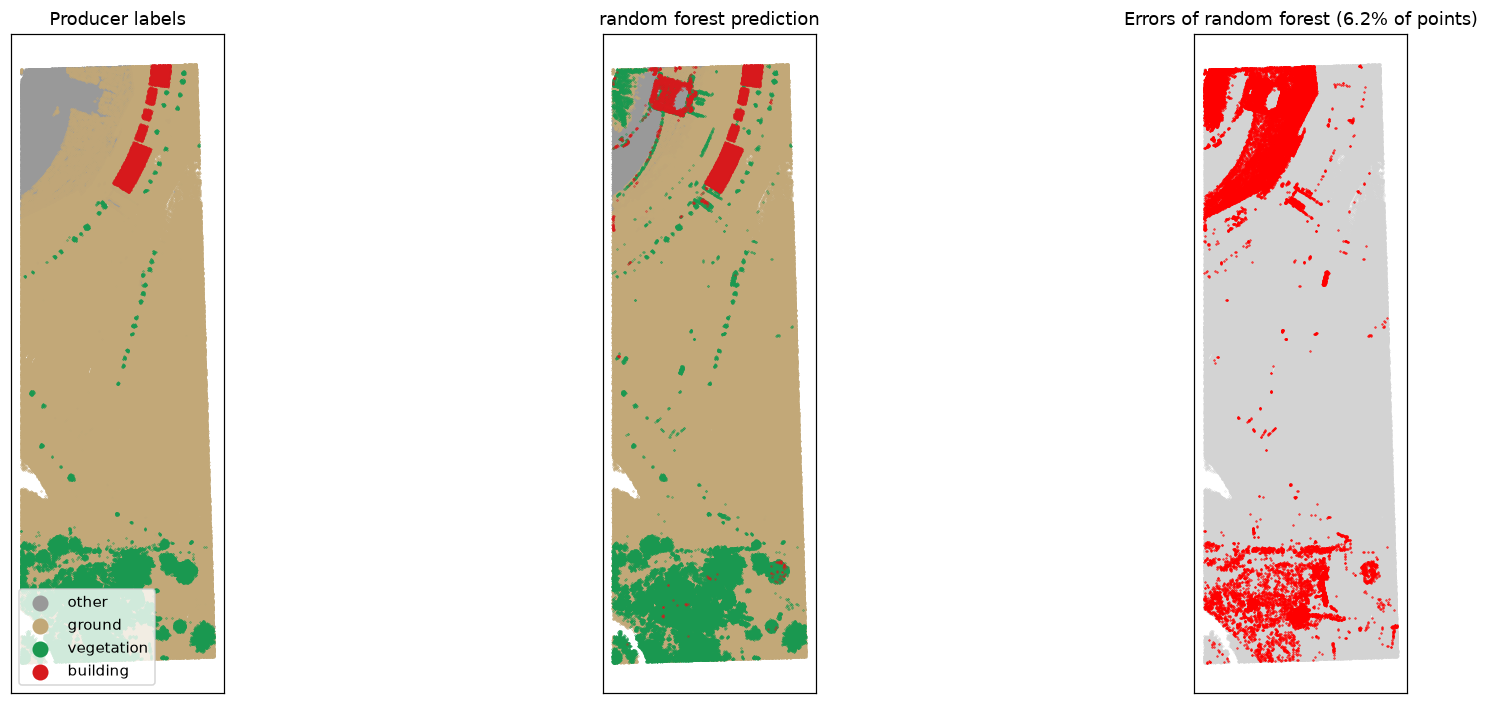

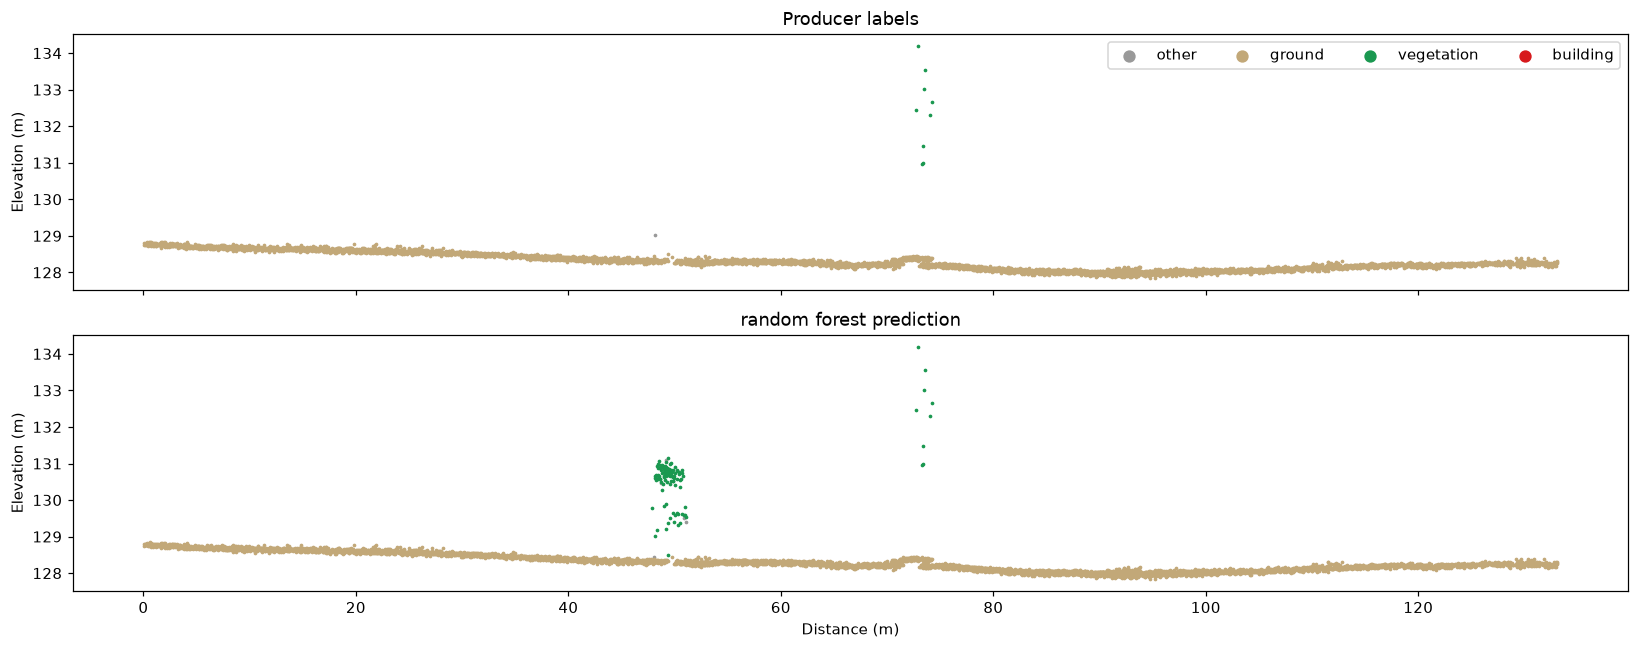

In [12]:
best = cmp["mean IoU"].idxmax()  # the model with the highest mean IoU
p = preds[best]  # its predictions
wrong = scored & (p != y_test)  # misclassified test points
fig, axes = plt.subplots(1, 3, figsize=(19, 6.5))  # three panels
for ax, (title, lab) in zip(axes[:2], (("Producer labels", y_test), (f"{best} prediction", p))):  # labels and prediction
    for k, col in cols.items():  # each class
        m = lab == k  # its points
        ax.scatter(test_pc.x[m], test_pc.y[m], s=0.1, color=col, label=NAMES[k])  # plan view
    ax.set(title=title, aspect="equal", xticks=[], yticks=[])  # labels
axes[0].legend(markerscale=30, loc="lower left")  # legend
axes[2].scatter(test_pc.x[scored], test_pc.y[scored], s=0.05, color="lightgrey")  # all scored points
axes[2].scatter(test_pc.x[wrong], test_pc.y[wrong], s=0.2, color="red")  # errors
# axis labels and title
axes[2].set(title=f"Errors of {best} ({wrong.sum() / scored.sum():.1%} of points)", aspect="equal", xticks=[], yticks=[])
plt.tight_layout(); plt.show()  # draw

ym = (y0 + y1) / 2  # a west-east line through the middle of the test area
sec_mask = np.abs(np.asarray(test_pc.y) - ym) < 3  # a 6 m wide slice
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)  # two panels
for ax, (title, lab) in zip(axes, (("Producer labels", y_test), (f"{best} prediction", p))):  # labels and prediction
    for k, col in cols.items():  # each class
        m = sec_mask & (lab == k)  # slice points of this class
        ax.scatter(test_pc.x[m] - AREAS["test"][0], test_pc.z[m], s=2, color=col, label=NAMES[k])  # profile
    ax.set(ylabel="Elevation (m)", title=title)  # labels
axes[0].legend(markerscale=5, ncol=4); axes[1].set_xlabel("Distance (m)"); plt.tight_layout(); plt.show()  # draw

All four models agree with the producer on most of the ground and the tree canopy (F1 above 0.95 and about 0.9). They differ on the two small classes:

- **Buildings.** The feature-based models are clearly better (F1 about 0.8 for the random forest against about 0.6 for the networks). Buildings are rare in this window: the training area holds a few buildings, most points from one large roof, and the validation strip only about 200 building points, so the networks see few examples and cannot select their best epoch for roofs. Hand-crafted height and planarity features generalise from few examples.
- **Other.** The networks recognise this heterogeneous class (cars, fences, low structures and points the producer left unlabelled) better than the random forest, because they learn context from the whole block rather than from one neighbourhood.

Overall the random forest gives the best mean IoU here, trains in seconds and needs no GPU. Deep networks need far more labelled data (benchmark datasets contain many millions of labelled points from many scenes) and longer training before they overtake well-designed features. Part of the remaining error is in the reference itself: the producer's labels on the stadium structures and the "other" class are not consistent.


## Exporting the classified cloud

The best model's predictions are written into the classification field of the test area and saved as LAZ, together with a table of the scores.


In [13]:
out_pc = test_pc.with_field("classification", np.where(p > 0, p, np.asarray(test_pc["classification"])).astype("uint8"))  # new codes
rs.lidar.write_las(out_pc, OUT / "autzen_test_classified.laz")  # classified LAZ
cmp.to_csv(OUT / "autzen_point_classification_scores.csv")  # scores
print(f"wrote {len(out_pc):,} points with {best} classes and the score table to {OUT}")  # report

wrote 478,705 points with random forest classes and the score table to outputs


## Summary and exercises

**Key points**

- Supervised point classification labels all classes at once from height, return structure, intensity and multi-scale eigenvalue features.
- Compute height above ground with a label-free ground filter, so the features do not contain the labels.
- Split the scene spatially. A random point-wise holdout puts near-identical neighbours in training and test sets and overstates accuracy.
- Random forest and gradient boosting on hand-crafted features are fast, interpretable and strong baselines.
- PointNet learns per-point and global features; PointNet++ adds local, multi-scale grouping. Both work on fixed-size blocks and average predictions from overlapping blocks.
- Report mean IoU and per-class F1, not only overall accuracy, and inspect errors on maps and cross-sections: reference labels have errors too.

**`geolattice.rsense` functions used:** `rs.lidar.read_las`, `rs.lidar.smrf`, `rs.lidar.dem`, `rs.lidar.normalize_heights`, `rs.lidar.point_feature_table`, `rs.lidar.train_point_classifier`, `rs.lidar.predict_point_classes`, `rs.lidar.write_las`, `geolattice.rsense.dl.pointnet.PointBlockDataset`, `PointNetSeg`, `PointNet2Seg`, `train_point_segmentation`, `predict_point_segmentation`.

**Exercises**

1. Train the random forest with one scale ($k = 16$) and with three scales (10, 40, 100). How do mean IoU and run time change?
2. Remove `height` from the features. Which class suffers most?
3. Train PointNet++ with 10 m and 30 m blocks. Which block size suits buildings, which suits ground?
4. Swap the training and test areas (train east, test west). Are the scores similar?
5. Apply the random forest trained on Autzen to the UB 2008 campus (about 1 point/m²). Does a model trained on dense data transfer to a sparse survey?
